<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/AFM_Resonance_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

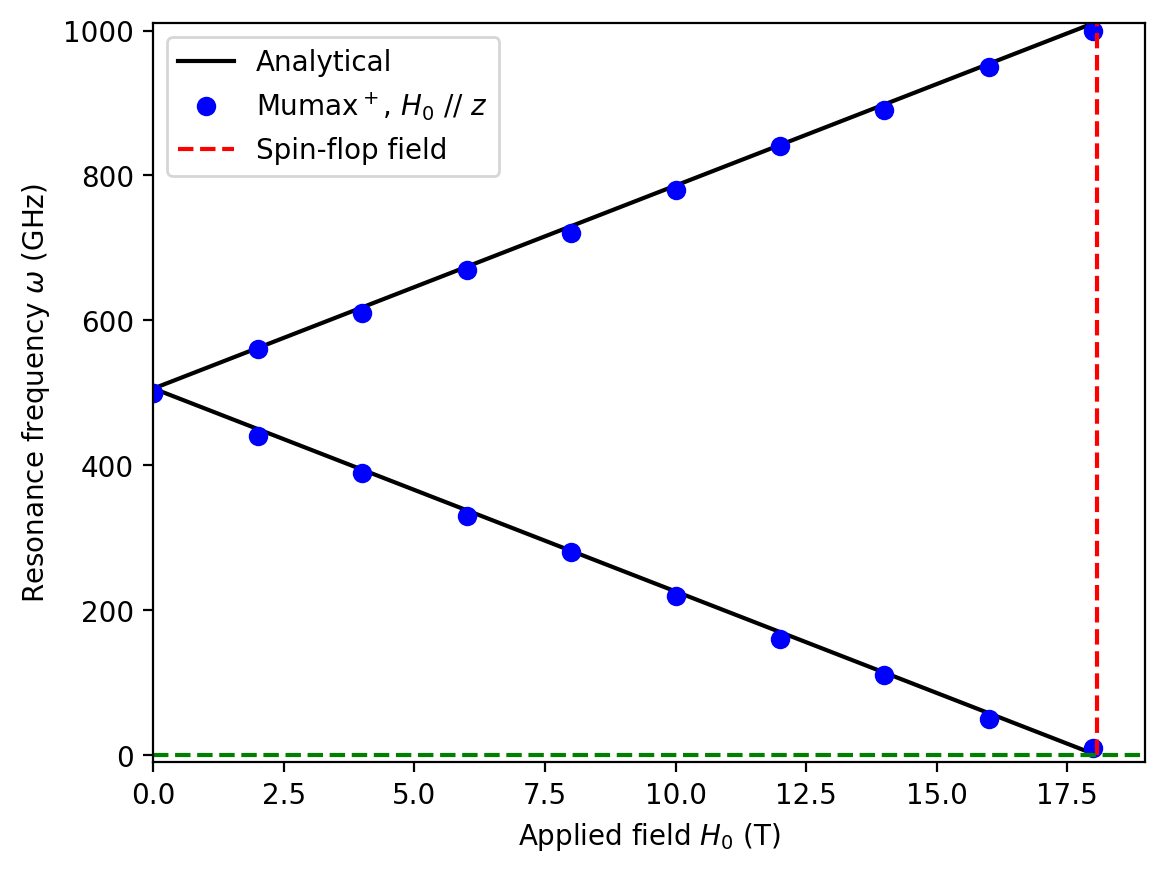

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import rfft, rfftfreq
from scipy.signal import find_peaks

from mumaxplus import Antiferromagnet, Grid, World
from mumaxplus.util.constants import GAMMALL_DEFAULT

plt.rcParams['figure.dpi'] = 200

Ms = 200e3
A0 = -100e-12
A = 10e-12
A12 = -15e-12
K = 1e3
a = 0.35e-9
mu0 = 1.256637062E-6
gamma = GAMMALL_DEFAULT / (2 * np.pi) # gyromagnetic ratio in Hz/T
alpha = 0

c = 1e-9
nx, ny, nz = 1, 1, 1
world = World(cellsize=(c, c, c))

magnet = Antiferromagnet(world, Grid((nx, ny, nz)))
magnet.afmex_nn = A12
magnet.afmex_cell = A0

for sub in magnet.sublattices:
    sub.msat = Ms
    sub.alpha = alpha
    sub.aex = A
    sub.ku1 = K
    sub.anisU = (0, 0, 1)

freq1, freq2 = [], []

N = 2000
tmax = 1e-10
timepoints = np.linspace(0, tmax, N)
xf = rfftfreq(N, tmax / N)

Ha = 2 * K / (mu0 * Ms)
He = -4 * A0 / (a * a * mu0 * Ms)
Hc = np.sqrt(2*He*Ha + Ha*Ha)
Hsf = np.sqrt(2 * He * Ha - Ha * Ha)*mu0 # spin-flop field in Teslas


H = np.linspace(0, int(Hsf), 10)
for Hext in H:

    world.bias_magnetic_field = (0, 0, Hext)

    # Create some asymmetry
    magnet.sub1.magnetization = (0, 0.1, 0.9)
    magnet.sub2.magnetization = (0, -0.1, -0.9)

    outputquantities = {"my1": lambda: magnet.sub1.magnetization.average()[1]}

    world.timesolver.time = 0
    output = world.timesolver.solve(timepoints, outputquantities)

    yf = rfft(output["my1"]) # FFT

    peaks, _ = find_peaks(np.abs(yf), height=20) # Find frequencies
    freq = [xf[peak] for peak in peaks]

    freq1.append(freq[0] * 1e-9)
    freq2.append(freq[-1] * 1e-9)

# Theoretical frequencies
f_ana1 = gamma * mu0 * (Hc + H/mu0) * 1e-9
f_ana2 = gamma * mu0 * (Hc - H/mu0) * 1e-9

fig = plt.figure()
plt.plot(H, f_ana1, 'k-', label="Analytical")
plt.plot(H, f_ana2, 'k-')
plt.plot(H, freq1, 'bo', label=r"Mumax$^+$, $H_0$ // $z$")
plt.plot(H, freq2, 'bo')
plt.vlines(Hsf, 0, max(f_ana1), 'r', '--', label="Spin-flop field")
plt.xlabel(r"Applied field $H_0$ (T)")
plt.ylabel(r"Resonance frequency $\omega$ (GHz)")
plt.xlim(0, max(H)+1)
plt.ylim([-10, max(f_ana1)])
plt.hlines([0], 0, max(H)+1, 'g', 'dashed')
plt.legend()
plt.show()